In [1]:
import matplotlib.pyplot as plt
import numpy as np

In [2]:
# Define the original sequence
original_sequence = "PDEAK"

# Define the amino acid categories
amino_acid_categories = {
    'polar': ['R', 'N', 'D', 'C', 'E', 'Q', 'H', 'K'],
    'non-polar': ['A', 'V', 'L', 'I', 'M', 'F', 'P', 'G', 'W'],
    'anionic': ['D', 'E'],
    'cationic': ['R', 'H', 'K']
}

# Define the color map for different amino acid categories
color_map = {
    'polar': '#9467bd',         # Purple
    'non-polar': '#ff7f0e',      # Orange
    'anionic': '#d62728',        # Red
    'cationic': '#2ca02c'        # Green
}

In [3]:

# Create a matrix to store the modified sequences
matrix = np.zeros((len(original_sequence), len(original_sequence)), dtype=object)

# Iterate over each position in the sequence
for i in range(len(original_sequence)):
    # Create a copy of the original sequence
    new_sequence = list(original_sequence)

    # Replace the amino acid at position i with alanine
    if new_sequence[i] != "A":
        new_sequence[i] = "a"
    # Store the modified sequence in the matrix
    matrix[i] = new_sequence

# Print the matrix of modified sequences
Ala_scan_seq = []

# Add the original sequence at the beginning
Ala_scan_seq.append(original_sequence)

for row in matrix:
    modified_peptide = ''.join(row)
    #if modified_peptide != original_sequence:
    Ala_scan_seq.append(modified_peptide)

# Print the Ala_scan_seq list
print(Ala_scan_seq)


['PDEAK', 'aDEAK', 'PaEAK', 'PDaAK', 'PDEAK', 'PDEAa']


##['P-D-E-N-K', 'A-D-E-N-K', 'P-A-E-N-K', 'P-D-A-N-K', 'P-D-E-A-K', 'P-D-E-N-A']

##Need all these sequences to be drawn like this image

####https://en.wikipedia.org/wiki/Alanine_scanning#/media/File:Alanine_Scan.png

#I tried few of the codes but cound't make it 




a
a
a
a


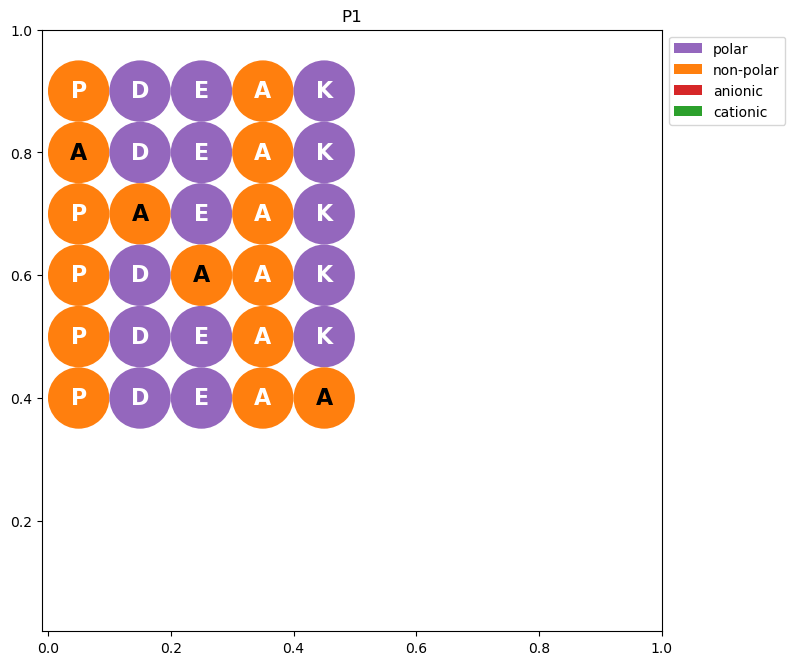

In [4]:
from matplotlib.patches import Patch,Ellipse

# Create a legend for the color representation
legend_elements = [
    Patch(facecolor=color_map['polar'], edgecolor='black', label='Polar'),
    Patch(facecolor=color_map['non-polar'], edgecolor='black', label='Non-polar'),
    Patch(facecolor=color_map['anionic'], edgecolor='black', label='Anionic'),
    Patch(facecolor=color_map['cationic'], edgecolor='black', label='Cationic')
]

# Create the figure and axes
figure, ax = plt.subplots(figsize=(8, 8))

# Calculate the maximum sequence length
max_length = max(len(seq) for seq in Ala_scan_seq)


# Iterate over the amino acid sequences

for i, seq in enumerate(Ala_scan_seq):
    for j,aa in enumerate(seq):
    
    # Get the category of the amino acid
        category = None
        for key, values in amino_acid_categories.items():
            if aa in values:
                category = key
                break
        
     # Skip the amino acid if no category is found
        if category is None:
            if aa == "a":
                category = "non-polar";
                print(aa);
                
        # Get the color for the category
        color = color_map[category]
        
        
        # Calculate the x and y positions based on the index
        x = (j+0.5) / ((max_length) + 5)
        y = 1 - (i+1) / (len(Ala_scan_seq)+ 4)
        
        # Calculate the radius based on the grid size
        radius = 0.3 / max(max_length, len(Ala_scan_seq))
        
        # Draw a circle for the amino acid
        circle = plt.Circle((x, y), radius, facecolor=color)
        
        # Add the circle to the plot
        ax.add_artist(circle)
        
        #print(seq,i,j,aa,x,y)
        # Add the amino acid letter as text inside the circle
        
        # Add the amino acid letter as text inside the circle
        if aa == 'a':
            ax.text(x, y, f"{aa.capitalize()}", color='black', va='center', ha='center', fontsize=16, weight='bold')
        else:
            ax.text(x, y, f"{aa}", color='white', va='center', ha='center', fontsize=16, weight='bold')
       
   
# Create the color legend
legend_elements = [Patch(facecolor=color, edgecolor='none', label=category) for category, color in color_map.items()]
legend = ax.legend(handles=legend_elements, loc='upper left', bbox_to_anchor=(1, 1))

# Set the background color of the legend
legend.get_frame().set_facecolor('white')
   
   
# Set the updated xlim and ylim

plt.xlim(-0.01, max_length / max_length)
plt.ylim(0.02, len(Ala_scan_seq)/len(Ala_scan_seq))

# Remove the axes
#ax.axis('off')
plt.title( 'P1' )
ax.set_aspect('equal')


plt.show()


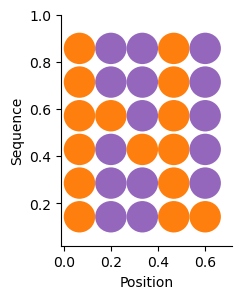

In [5]:
from matplotlib.patches import Patch

# Create a legend for the color representation
legend_elements = [
    Patch(facecolor=color_map['polar'], edgecolor='black', label='Polar'),
    Patch(facecolor=color_map['non-polar'], edgecolor='black', label='Non-polar'),
    Patch(facecolor=color_map['anionic'], edgecolor='black', label='Anionic'),
    Patch(facecolor=color_map['cationic'], edgecolor='black', label='Cationic')
]

# Calculate the maximum circle radius
max_radius = 0.4 / max(max_length, len(Ala_scan_seq))

# Create a list to store the circle objects
circles = []

# Iterate over the amino acid sequences
for i, seq in enumerate(Ala_scan_seq):
    for j, aa in enumerate(seq):
        # Calculate the x and y positions based on the index
        x = (j + 0.5) / (max_length + 2.5)
        y = 1 - (i + 1) / (len(Ala_scan_seq) + 1)

        # Calculate the radius based on the grid size
        radius = 0.4 / max(max_length, len(Ala_scan_seq))

        # Get the category of the amino acid
        category = None
        for key, values in amino_acid_categories.items():
            if aa in values:
                category = key
                break

        # Skip the amino acid if no category is found
        if category is None:
            if aa == 'a':
                category = 'non-polar'

        # Get the color for the category
        color = color_map[category]

        # Create the circle object
        circle = plt.Circle((x, y), radius, facecolor=color)

        # Add the circle to the list
        circles.append(circle)

# Sort the circles based on radius in descending order
circles.sort(key=lambda c: c.radius, reverse=True)

# Create the figure and axes
fig, ax = plt.subplots(figsize=(max_length / 2, len(Ala_scan_seq) / 2))

# Add the circles to the plot in the desired order
for circle in circles:
    ax.add_artist(circle)

# Set the x-axis limits
plt.xlim(-0.01, max_length / (max_length + 2))

# Set the y-axis limits
plt.ylim(0.02, 1)

# Set the aspect ratio to equal
ax.set_aspect('equal')

# Remove the spines
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)

# Add axis labels
plt.xlabel('Position')
plt.ylabel('Sequence')

# Show the plot
plt.show()


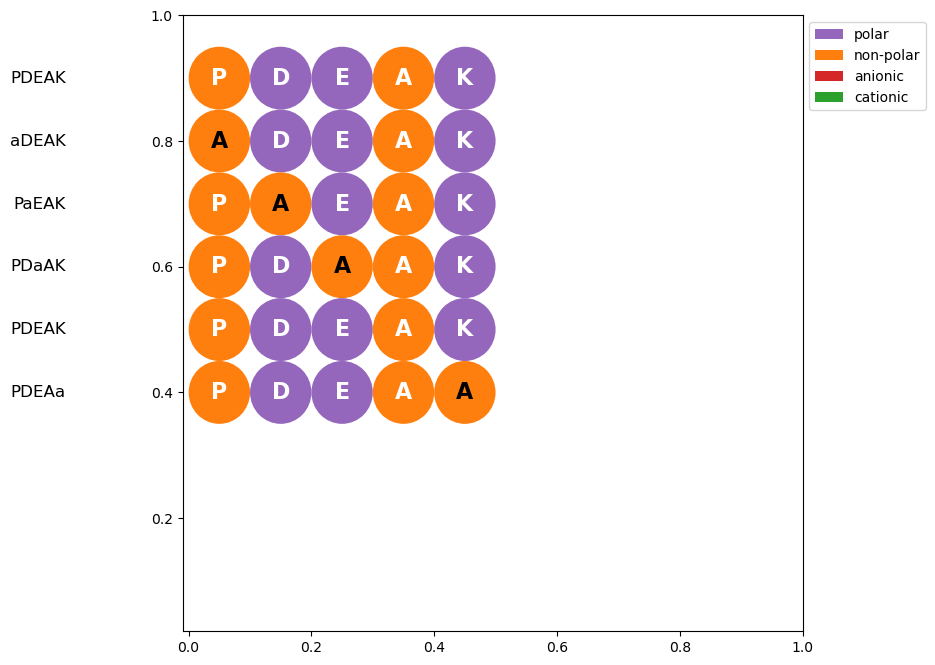

In [288]:
from matplotlib.patches import Patch

# Create the figure and axes
figure, ax = plt.subplots(figsize=(8, 8))

# Calculate the maximum sequence length
max_length = max(len(seq) for seq in Ala_scan_seq)

# Iterate over the amino acid sequences
for i, seq in enumerate(Ala_scan_seq):
    for j, aa in enumerate(seq):
        # Get the category of the amino acid
        category = None
        for key, values in amino_acid_categories.items():
            if aa in values:
                category = key
                break

        # Skip the amino acid if no category is found
        if category is None:
            if aa == 'a':
                category = 'non-polar'

        # Get the color for the category
        color = color_map[category]

        # Calculate the x and y positions based on the index
        x = (j + 0.5) / (max_length + 5)
        y = 1 - (i + 1) / (len(Ala_scan_seq) + 4)

        # Calculate the radius based on the grid size
        radius = 0.3 / max(max_length, len(Ala_scan_seq))

        # Draw a circle for the amino acid
        circle = plt.Circle((x, y), radius, facecolor=color)

        # Add the circle to the plot
        ax.add_artist(circle)

        # Add the amino acid letter as text inside the circle
        if aa == 'a':
            ax.text(x, y, f"{aa.capitalize()}", color='black', va='center', ha='center', fontsize=16, weight='bold')
        else:
            ax.text(x, y, f"{aa}", color='white', va='center', ha='center', fontsize=16, weight='bold')

# Create the color legend
legend_elements = [Patch(facecolor=color, edgecolor='none', label=category) for category, color in color_map.items()]
legend = ax.legend(handles=legend_elements, loc='upper left', bbox_to_anchor=(1, 1))

# Set the background color of the legend
legend.get_frame().set_facecolor('white')

# Set the x-axis limits
plt.xlim(-0.01, max_length / max_length)

# Set the y-axis limits
plt.ylim(0.02, len(Ala_scan_seq) / len(Ala_scan_seq))


# Remove the axes
#ax.axis('off')

# Add the amino acid sequences as text
for i, seq in enumerate(Ala_scan_seq):
    ax.text(-0.2, 1 - (i + 1) / (len(Ala_scan_seq) + 4), seq, color='black', va='center', ha='right', fontsize=12)

# Display the plot
plt.show()
